# Discrete-Time Convolution — Interactive Demo

**Topic: discrete convolution and LTI filtering**  
Inspired by the [DSPFirst Discrete Convolution Demo (`dconvdemo`)](https://dspfirst.gatech.edu/matlab/#dconvdemo).

**Goal:** understand convolution *one output sample at a time*: **flip → shift → multiply → sum**.

The interactive controls let you:
- Choose different finite-length sequences $x[n]$ and $h[n]$, including your own samples.
- Move the **output index $n$** with a slider, **Previous / Next**, or **Play**.
- Compare $x[k]$, $h[k]$, the shifted/flipped $h[n-k]$, their pointwise product, and the growing output $y[n]$.
- **Hide the output** for a classroom prediction exercise, reveal it one sample at a time, or reveal everything.

The graphs are discrete-time sequences: connecting markers are only visual guides, not values between samples.

## 1 · What does the convolution sum mean?

For a discrete-time LTI system with input $x[n]$ and impulse response $h[n]$,

$$
\boxed{y[n] = (x*h)[n] = \sum_{k=-\infty}^{\infty} x[k]\,h[n-k]}
$$

To find **one output sample** $y[n]$:

1. **Flip:** start with $h[k]$ and reverse its index to obtain $h[-k]$.
2. **Shift:** translate it by $n$ to obtain $h[n-k]$.
3. **Multiply:** find the product $x[k]h[n-k]$ at each integer $k$.
4. **Sum:** add those products; the result is $y[n]$.

For finite sequences, values outside their stated supports are **zero**. If $x$ spans indices $n_x^{\min}$ to $n_x^{\max}$ and $h$ spans $n_h^{\min}$ to $n_h^{\max}$, then the convolution can be nonzero only for

$$
n_x^{\min}+n_h^{\min}\ \leq\ n\ \leq\ n_x^{\max}+n_h^{\max}.
$$

Unlike circular convolution, the demo computes **ordinary linear convolution** (no wraparound).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

try:
    import ipywidgets as widgets
    WIDGETS_AVAILABLE = True
except ImportError:
    widgets = None
    WIDGETS_AVAILABLE = False
    print('ipywidgets is not installed. Install it with: %pip install ipywidgets')

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True})

## 2 · Define sequences with their time origins

Represent each finite discrete-time signal using an array of values **and the index of its first value**. For example, $x[-1]=1$, $x[0]=2$, $x[1]=1$ becomes `values=[1, 2, 1], start=-1`.

Try these pairs in the demo:
- **Two rectangles** → a triangular / trapezoidal convolution.
- **Rectangular input + 3-point moving average** → smoothing and a transition at each edge.
- **Input + first difference** → changes in the input are highlighted.
- **Input + unit impulse** → identity or a simple delay.
- **Input + echo impulse response** → a delayed copy is added to the original.

In [2]:
INPUT_PRESETS = {
    'Rectangular pulse (5 samples)': (np.ones(5), 0),
    'Triangle (centered)': (np.array([1, 2, 3, 2, 1], dtype=float), -2),
    'Alternating signs': (np.array([1, -1, 1, -1, 1], dtype=float), 0),
    'Exponential decay': (0.70 ** np.arange(8, dtype=float), 0),
    'Two separated impulses': (np.array([1, 0, 0, 0, 0.75]), -1),
    'Short arbitrary sequence': (np.array([1, 2, -1, 1], dtype=float), -1),
    'Unit impulse': (np.array([1.0]), 0),
    'Custom': None,
}
FILTER_PRESETS = {
    'Rectangular pulse (4 samples)': (np.ones(4), 0),
    '3-point moving average': (np.ones(3) / 3, 0),
    'First difference [1, -1]': (np.array([1.0, -1.0]), 0),
    'Unit impulse': (np.array([1.0]), 0),
    'Delayed impulse (n = 2)': (np.array([1.0]), 2),
    'Echo [1, 0, 0, 0.6]': (np.array([1.0, 0.0, 0.0, 0.6]), 0),
    'Exponential decay': (0.65 ** np.arange(6, dtype=float), 0),
    'Custom': None,
}


def parse_values(text, max_length=20):
    """Parse values separated by commas or spaces (supports surrounding [brackets])."""
    raw = text.strip().strip('[]').replace(',', ' ').replace(';', ' ')
    tokens = raw.split()
    if not tokens:
        raise ValueError('Enter at least one sample (e.g. 1, 2, -1).')
    if len(tokens) > max_length:
        raise ValueError(f'Use at most {max_length} samples so the demo stays readable.')
    try:
        values = np.array([float(token) for token in tokens], dtype=float)
    except ValueError as exc:
        raise ValueError('Samples must be numbers, separated by commas or spaces.') from exc
    if not np.all(np.isfinite(values)):
        raise ValueError('Samples must be finite.')
    return values


def get_signal(preset_name, options, custom_text='', custom_start=0):
    if preset_name == 'Custom':
        return parse_values(custom_text), int(custom_start)
    values, start = options[preset_name]
    return np.array(values, dtype=float), int(start)


def samples_at(values, start, positions):
    """x[positions] for a finite sequence with x[start] = values[0]."""
    positions = np.asarray(positions, dtype=int)
    offsets = positions - start
    result = np.zeros(positions.shape, dtype=float)
    valid = (offsets >= 0) & (offsets < len(values))
    result[valid] = values[offsets[valid]]
    return result


def linear_convolution(x, x_start, h, h_start):
    """Return convolution samples and their *correct* discrete-time indices."""
    y = np.convolve(x, h, mode='full')
    y_start = x_start + h_start
    n_y = np.arange(y_start, y_start + len(y))
    return n_y, y


def step_terms(x, x_start, h, h_start, n):
    """Table entries for y[n] = sum_k x[k] h[n-k]."""
    k_low = min(x_start, n - (h_start + len(h) - 1))
    k_high = max(x_start + len(x) - 1, n - h_start)
    k = np.arange(k_low, k_high + 1, dtype=int)
    xv = samples_at(x, x_start, k)
    hv = samples_at(h, h_start, n - k)
    return k, xv, hv, xv * hv


# Small numerical sanity check, including shifted/negative indices
_x, _h = np.array([1, 2, 1.]), np.array([1., -1.])
_n, _y = linear_convolution(_x, -1, _h, 1)
assert np.array_equal(_n, [0, 1, 2, 3])
assert np.allclose(_y, [1, 1, -1, -1])
for _step_n, _target in zip(_n, _y):
    assert np.isclose(step_terms(_x, -1, _h, 1, int(_step_n))[-1].sum(), _target)
print('Convolution indexing and step-by-step sum checks passed.')

Convolution indexing and step-by-step sum checks passed.


## 3 · Interactive flip–shift–multiply–sum demo

**How to use it:** select $x[n]$ and $h[n]$, then move **$n$**. The middle plot overlays the fixed $x[k]$ and the *time-reversed, translated* $h[n-k]$. The product plot shows the samples that contribute to $y[n]$.

The bottom plot is a **running reveal of the convolution**. With **Hide output**, students can calculate the current sum before revealing it. Use **Play** to animate the shift. A table is available to inspect the individual products.

**Important:** the slider moves the **output index $n$**, not the dummy summation index $k$.

In [3]:
def _nice(v):
    return f'{v:.3g}'


def draw_convolution_step(x, x_start, h, h_start, n, reveal='Up to current n',
                          show_table=False, save_path=None):
    """Plot one convolution step; also usable outside the widget interface."""
    x = np.asarray(x, dtype=float)
    h = np.asarray(h, dtype=float)
    n_y, y = linear_convolution(x, x_start, h, h_start)
    n = int(np.clip(n, n_y[0], n_y[-1]))
    k, x_aligned, h_aligned, products = step_terms(x, x_start, h, h_start, n)
    y_current = float(products.sum())
    assert np.isclose(y_current, y[n - n_y[0]])

    from matplotlib.gridspec import GridSpec
    fig = plt.figure(figsize=(12, 10))
    gs = GridSpec(4, 2, figure=fig, height_ratios=[1, 1.25, 1, 1.05],
                  hspace=0.53, wspace=0.27)
    ax_x = fig.add_subplot(gs[0, 0])
    ax_h = fig.add_subplot(gs[0, 1])
    ax_overlap = fig.add_subplot(gs[1, :])
    ax_prod = fig.add_subplot(gs[2, :])
    ax_y = fig.add_subplot(gs[3, :])
    x_idx = np.arange(x_start, x_start + len(x))
    h_idx = np.arange(h_start, h_start + len(h))

    for ax, idx, values, name in [(ax_x, x_idx, x, r'$x[k]$'),
                                   (ax_h, h_idx, h, r'$h[k]$')]:
        ax.stem(idx, values, basefmt=' ')
        ax.axhline(0, linewidth=0.8)
        ax.set_title('Original ' + name)
        ax.set_xlabel('$k$')
        ax.set_ylabel('Amplitude')
        ax.set_xticks(idx if len(idx) <= 12 else idx[::2])
        ax.margins(x=0.07, y=0.2)

    ax_overlap.plot(k, x_aligned, 'o-', linewidth=1.5, label=r'Fixed $x[k]$')
    ax_overlap.plot(k, h_aligned, 's--', linewidth=1.5,
                    label=rf'Flipped + shifted $h[{n}-k]$')
    ax_overlap.axhline(0, linewidth=0.8)
    ax_overlap.set_title(rf'Align at output index $n={n}$: $x[k]$ and $h[n-k]$')
    ax_overlap.set_ylabel('Amplitude')
    ax_overlap.set_xlabel('Summation index $k$')
    ax_overlap.set_xticks(k)
    ax_overlap.legend(loc='upper right')
    ax_overlap.margins(x=0.03, y=0.18)

    ax_prod.stem(k, products, basefmt=' ')
    ax_prod.axhline(0, linewidth=0.8)
    ax_prod.set_title(rf'Multiply sample by sample: $x[k] h[{n}-k]$')
    ax_prod.set_xlabel('Summation index $k$')
    ax_prod.set_ylabel('Product')
    ax_prod.set_xticks(k)
    ax_prod.margins(x=0.03, y=0.22)

    if reveal == 'Show all':
        indices, shown = n_y, y
    elif reveal == 'Up to current n':
        mask = n_y <= n
        indices, shown = n_y[mask], y[mask]
    else:  # Hide output
        indices, shown = np.array([], dtype=int), np.array([])
    if len(indices):
        ax_y.stem(indices, shown, basefmt=' ')
        ax_y.plot([n], [y_current], marker='o', markersize=11,
                  fillstyle='none', linewidth=0)
    ax_y.axvline(n, linestyle=':', linewidth=1.5)
    ax_y.axhline(0, linewidth=0.8)
    ax_y.set_xlim(n_y[0] - 0.7, n_y[-1] + 0.7)
    ax_y.set_ylim(-max(0.3, 1.25 * max(abs(y))),
                   max(0.3, 1.25 * max(abs(y))))
    ax_y.set_xticks(n_y if len(n_y) <= 21 else n_y[::2])
    ax_y.set_xlabel('Output index $n$')
    ax_y.set_ylabel('Amplitude')
    ax_y.set_title('Output $y[n]$: ' +
                   ('predict the hidden value' if reveal == 'Hide output'
                    else f'y[{n}] = {_nice(y_current)}'))
    fig.suptitle('Discrete convolution: flip → shift → multiply → sum',
                 fontsize=15, y=0.993)

    if save_path is not None:
        fig.savefig(save_path, dpi=160, bbox_inches='tight')
    plt.show()

    active = np.flatnonzero(np.abs(products) > 1e-12)
    if reveal == 'Hide output':
        print(f'At n={n}, add the products in the third plot. What is y[{n}]?')
    else:
        terms = ' + '.join(_nice(products[i]) for i in active)
        print(f'y[{n}] = ' + (terms if terms else '0') + f' = {_nice(y_current)}')
    print(f'Output support: n={n_y[0]}, ..., {n_y[-1]} ' +
          f'({len(y)} samples = {len(x)} + {len(h)} - 1).')

    if show_table:
        print('\nTerms contributing at this shift:')
        print(f'{"k":>6} | {"x[k]":>10} | {"h[n-k]":>10} | {"product":>10}')
        print('-' * 48)
        for ki, xi, hi, pi in zip(k, x_aligned, h_aligned, products):
            if abs(xi) > 1e-12 or abs(hi) > 1e-12:
                print(f'{ki:>6} | {xi:>10.3g} | {hi:>10.3g} | {pi:>10.3g}')
        if reveal != 'Hide output':
            print(f'  SUM = {_nice(y_current)}')
    return n_y, y

In [ ]:
def convolution_explorer():
    """Create classroom-friendly widgets, including a dynamic n slider and Play."""
    if not WIDGETS_AVAILABLE:
        print('Install ipywidgets to enable the controls: %pip install ipywidgets')
        draw_convolution_step(np.ones(5), 0, np.ones(4), 0, n=3)
        return None

    x_choice = widgets.Dropdown(options=list(INPUT_PRESETS),
                                value='Rectangular pulse (5 samples)',
                                description='Input x:', style={'description_width':'initial'},
                                layout=widgets.Layout(width='370px'))
    h_choice = widgets.Dropdown(options=list(FILTER_PRESETS),
                                value='Rectangular pulse (4 samples)',
                                description='Filter h:', style={'description_width':'initial'},
                                layout=widgets.Layout(width='370px'))
    x_text = widgets.Text(value='1, 2, -1, 1', description='Custom x:',
                          style={'description_width':'initial'},
                          layout=widgets.Layout(width='300px'))
    h_text = widgets.Text(value='1, -1', description='Custom h:',
                          style={'description_width':'initial'},
                          layout=widgets.Layout(width='300px'))
    x_start = widgets.IntText(value=0, description='First x index:',
                              style={'description_width':'initial'},
                              layout=widgets.Layout(width='170px'))
    h_start = widgets.IntText(value=0, description='First h index:',
                              style={'description_width':'initial'},
                              layout=widgets.Layout(width='170px'))
    n_slider = widgets.IntSlider(value=0, min=0, max=7, step=1,
                                 description='Output n:', continuous_update=False,
                                 style={'description_width':'initial'},
                                 layout=widgets.Layout(width='530px'))
    play = widgets.Play(value=0, min=0, max=7, step=1, interval=850,
                        description='Play', disabled=False)
    widgets.jslink((play, 'value'), (n_slider, 'value'))
    prev = widgets.Button(description='◀ Previous', layout=widgets.Layout(width='130px'))
    nxt = widgets.Button(description='Next ▶', layout=widgets.Layout(width='100px'))
    reveal = widgets.ToggleButtons(options=['Hide output', 'Up to current n', 'Show all'],
                                   value='Up to current n', description='Show:',
                                   style={'description_width':'initial'})
    table = widgets.Checkbox(value=False, description='Show multiplication table', indent=False)
    output = widgets.Output()
    state = {'error':None}

    def current_signals():
        x, ix = get_signal(x_choice.value, INPUT_PRESETS, x_text.value, x_start.value)
        h, ih = get_signal(h_choice.value, FILTER_PRESETS, h_text.value, h_start.value)
        return x, ix, h, ih

    def update_range(change=None):
        try:
            x, ix, h, ih = current_signals()
            ns, _ = linear_convolution(x, ix, h, ih)
            # The widget min/max are changed before value is clamped.
            desired = int(np.clip(n_slider.value, ns[0], ns[-1]))
            n_slider.min = min(n_slider.min, int(ns[0]))
            n_slider.max = max(n_slider.max, int(ns[-1]))
            n_slider.min = int(ns[0]); n_slider.max = int(ns[-1])
            n_slider.value = desired
            # Expand safely first, then narrow: works even if the new range
            # lies completely above/below the previous Play range.
            play.min = min(play.min, int(ns[0]))
            play.max = max(play.max, int(ns[-1]))
            play.min, play.max = int(ns[0]), int(ns[-1])
            play.value = desired
            state['error'] = None
        except ValueError as exc:
            state['error'] = str(exc)
        redraw()

    def redraw(change=None):
        with output:
            clear_output(wait=True)
            if state['error'] is not None:
                print('Check the custom sequence:', state['error'])
                return
            try:
                x, ix, h, ih = current_signals()
                draw_convolution_step(x, ix, h, ih, n_slider.value,
                                      reveal.value, table.value)
            except (ValueError, TypeError) as exc:
                print('Cannot draw:', exc)

    def do_prev(_): n_slider.value = max(n_slider.min, n_slider.value - 1)
    def do_next(_): n_slider.value = min(n_slider.max, n_slider.value + 1)
    prev.on_click(do_prev); nxt.on_click(do_next)

    for control in (x_choice, h_choice, x_text, h_text, x_start, h_start):
        control.observe(update_range, names='value')
    for control in (n_slider, reveal, table):
        control.observe(redraw, names='value')

    # Only the relevant custom editors become visible for the chosen preset.
    def visibility(change=None):
        x_custom = x_choice.value == 'Custom'
        h_custom = h_choice.value == 'Custom'
        for control in (x_text, x_start):
            control.layout.display = '' if x_custom else 'none'
        for control in (h_text, h_start):
            control.layout.display = '' if h_custom else 'none'
    x_choice.observe(visibility, names='value')
    h_choice.observe(visibility, names='value')
    visibility()

    ui = widgets.VBox([
        widgets.HTML('<b>Sequences</b>'),
        widgets.HBox([x_choice, h_choice]),
        widgets.HBox([x_text, x_start]),
        widgets.HBox([h_text, h_start]),
        widgets.HTML('<b>Slide the flipped filter h[n−k]</b>'),
        widgets.HBox([play, prev, nxt]),
        n_slider,
        widgets.HBox([reveal, table]),
        output,
    ])
    display(ui)
    update_range()
    return ui


explorer = convolution_explorer()

## 4 · Worked example: calculate one output value by hand

Consider $x[n] = [1,\,2,\,1]$ and $h[n] = [1,\,-1]$, both starting at index 0.

At $n=2$, only two pairs overlap:

$$
\begin{aligned}
y[2] &= \sum_k x[k]h[2-k] \\
     &= x[1]h[1] + x[2]h[0] \\
     &= 2(-1) + 1(1) = -1.
\end{aligned}
$$

Run the following cell and compare this hand calculation with `np.convolve`. Then reproduce the same example using **Custom** sequences in the interactive explorer.

n: [0 1 2 3]
y: [ 1.  1. -1. -1.]
NumPy: [ 1.  1. -1. -1.]


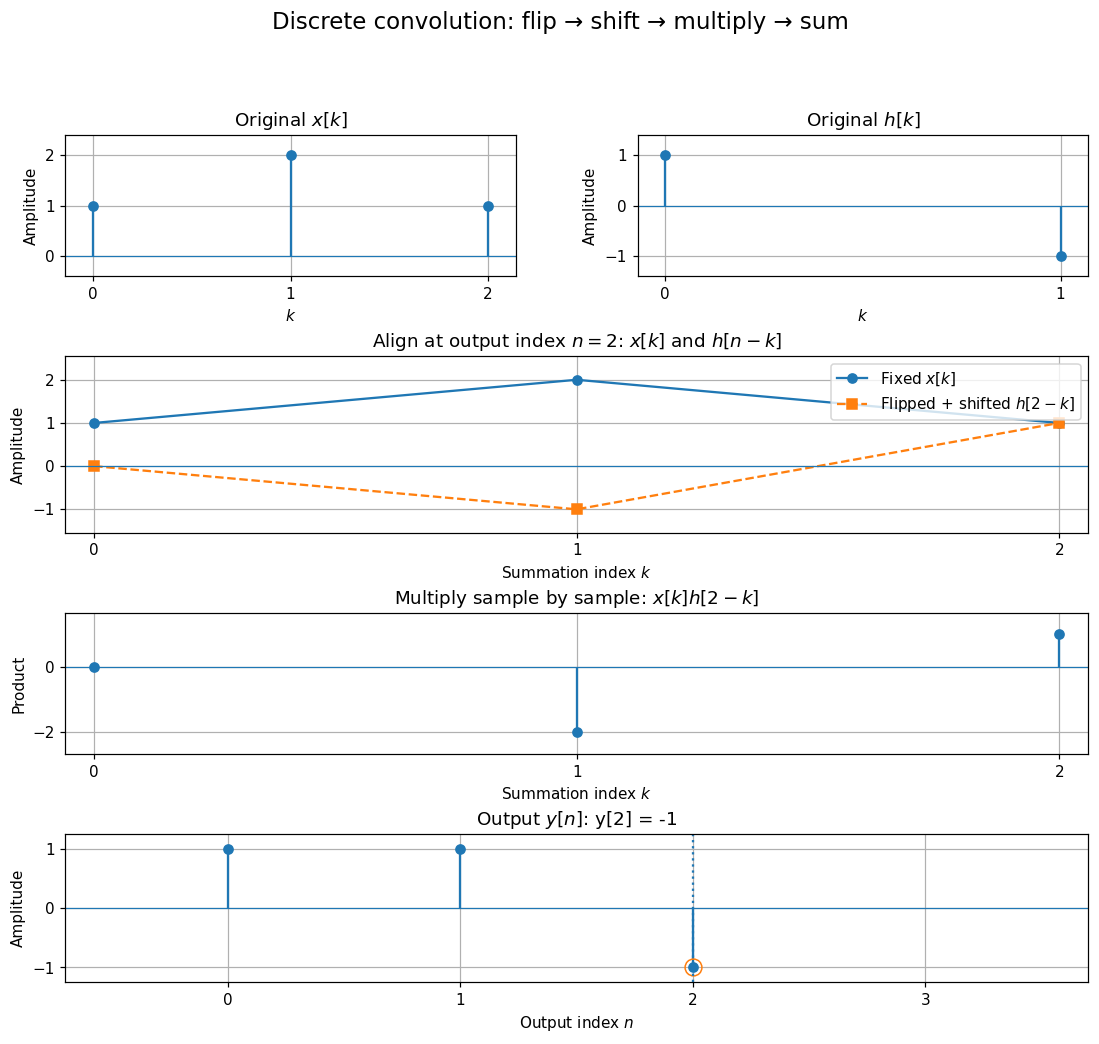

y[2] = -2 + 1 = -1
Output support: n=0, ..., 3 (4 samples = 3 + 2 - 1).

Terms contributing at this shift:
     k |       x[k] |     h[n-k] |    product
------------------------------------------------
     0 |          1 |          0 |          0
     1 |          2 |         -1 |         -2
     2 |          1 |          1 |          1
  SUM = -1


In [5]:
x = np.array([1., 2., 1.])
h = np.array([1., -1.])
n_values, y = linear_convolution(x, 0, h, 0)
print('n:', n_values)
print('y:', y)
print('NumPy:', np.convolve(x, h))
assert np.allclose(y, [1, 1, -1, -1])

# One step shown with the flipped filter and the product:
_, _ = draw_convolution_step(x, 0, h, 0, n=2, reveal='Up to current n', show_table=True)

## 5 · Convolution as FIR filtering

The impulse response $h[n]$ describes a discrete-time **linear, time-invariant (LTI)** filter:

$$y[n] = \sum_k h[k] x[n-k].$$

- **Moving average:** $h[n] = [1/3, 1/3, 1/3]$ smooths rapid changes.
- **First difference:** $h[n] = [1,-1]$ emphasizes sample-to-sample changes.
- **Delay:** $h[n] = \delta[n-2]$ produces $y[n]=x[n-2]$.

Convolution is **commutative** ($x*h=h*x$), but when studying filtering we normally interpret $x$ as the input and $h$ as the system response.

This next plot illustrates the three examples using exactly the same input signal. Afterwards, select the filters in the interactive explorer and watch the terms in each output sample.

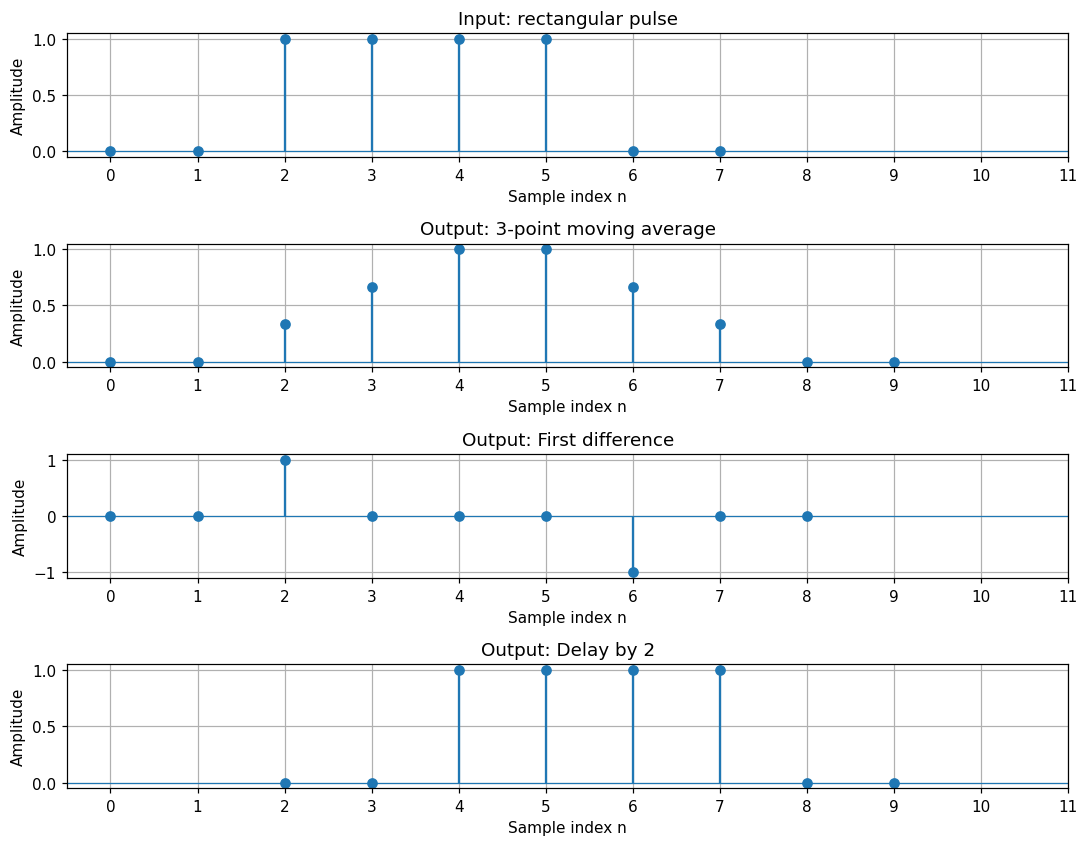

In [6]:
def filtering_examples():
    x = np.array([0., 0., 1., 1., 1., 1., 0., 0.])
    cases = [
        ('3-point moving average', np.ones(3)/3, 0),
        ('First difference', np.array([1., -1.]), 0),
        ('Delay by 2', np.array([1.]), 2),
    ]
    fig, axes = plt.subplots(4, 1, figsize=(10, 7.8))
    axes[0].stem(np.arange(len(x)), x, basefmt=' ')
    axes[0].set_title('Input: rectangular pulse')
    for ax, (name, h, first_h) in zip(axes[1:], cases):
        n_values, y = linear_convolution(x, 0, h, first_h)
        ax.stem(n_values, y, basefmt=' ')
        ax.set_title('Output: ' + name)
    for ax in axes:
        ax.axhline(0, linewidth=0.8)
        ax.set_xlabel('Sample index n')
        ax.set_ylabel('Amplitude')
        ax.set_xticks(np.arange(0, 12))
        ax.set_xlim(-0.5, 11)
    plt.tight_layout()
    plt.show()

filtering_examples()

## 6 · Exercises to try in the interactive explorer

1. **Two rectangles:** choose the 5-sample rectangular input and 4-sample rectangular filter. How many samples does the output have? Why does it rise, remain flat briefly, then fall?
2. **Predict before revealing:** select **Hide output** and stop at $n=3$. Compute the sum in the product plot. Then reveal the result.
3. **Impulse and delay:** choose the unit impulse or delayed impulse for $h[n]$. What happens to the input? Why does this follow from the convolution formula?
4. **Smoothing versus differences:** use the same rectangular input with a 3-point moving average and with the first difference filter. Which one emphasizes constant regions? Which one emphasizes transitions?
5. **Negative indices:** select **Custom** input `1, 2, 1` with first index `-1`; select **Custom** filter `1, -1` with first index `1`. Verify that the *values* of the convolution stay the same but that their output indices shift.
6. **Commutativity:** interchange $x$ and $h$. Compare the output samples and their index positions.

**Takeaways:** at each $n$, flip $h[k]$, shift it to $h[n-k]$, multiply by $x[k]$, and sum. A filter's impulse response determines how its input is transformed. Unlike circular convolution, linear convolution does not wrap the ends around.

**Reference:** DSPFirst — [Discrete Convolution Demo](https://dspfirst.gatech.edu/matlab/#dconvdemo). This notebook is an independent Python teaching implementation, not a port of its MATLAB code.